# EDA: characterise the Corpus

Exploratory data analysis of the SEC EDGAR Corpus supplied with the assessment.
Every analysis loads Filings through the `edgar_rag` Corpus seam, the same code the
indexer and API will use, and ends with a **so the design does X** conclusion.
Findings are collected in [`docs/findings.md`](../../docs/findings.md).

This file is the source of truth (jupytext percent format). The paired `.ipynb`
is generated with `make eda` and is never edited by hand.

In [1]:
import json
import re
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

from edgar_rag.corpus import (
    DEFAULT_CORPUS_DIR,
    TRACKED_MIN_QUARTERS,
    UNSECTIONED,
    check_manifest,
    consecutive_quarters,
    load_corpus,
    load_sector_table,
)

filings = load_corpus()
print(f"{len(filings)} Filings from {len({f.ticker for f in filings})} Companies")

246 Filings from 54 Companies


## 1. Inventory and coverage

### 1.1 Filings per Company and the coverage grid

How many Filings does each Company have, of which Form Type, and in which Calendar
Quarters? Calendar Quarter is taken from the header as written. Filings whose header
has no Calendar Quarter are counted in a separate column; deriving their Report
Period is a later analysis.

In [2]:
df = pd.DataFrame(
    {
        "ticker": f.ticker,
        "company": f.company,
        "form_type": f.form_type,
        "calendar_quarter": f.calendar_quarter,
        "report_period": f.report_period,
        "filing_date": f.filing_date,
    }
    for f in filings
)

per_company = (
    df.pivot_table(index="ticker", columns="form_type", values="company", aggfunc="count")
    .fillna(0)
    .astype(int)
)
per_company["total"] = per_company.sum(axis=1)
per_company = per_company.sort_values(["total", "10-Q"], ascending=False)
per_company.T

ticker,DIS,JNJ,AAPL,AMZN,MSFT,NVDA,TSLA,XOM,KO,PFE,...,PG,RTX,SBUX,T,TGT,TMO,UPS,V,VZ,WMT
form_type,,,,,,,,,,,,,,,,,,,,,
10-K,4,5,4,4,4,4,4,4,3,3,...,1,1,1,1,1,1,1,1,1,1
10-Q,13,12,12,12,12,12,12,12,12,12,...,0,0,0,0,0,0,0,0,0,0
total,17,17,16,16,16,16,16,16,15,15,...,1,1,1,1,1,1,1,1,1,1


In [3]:
filings_per_company = Counter(per_company["total"])
pd.DataFrame(
    sorted(filings_per_company.items(), reverse=True),
    columns=["Filings per Company", "Companies"],
).set_index("Filings per Company").T

Filings per Company,17,16,15,14,8,4,2,1
Companies,2,6,3,1,1,2,2,37


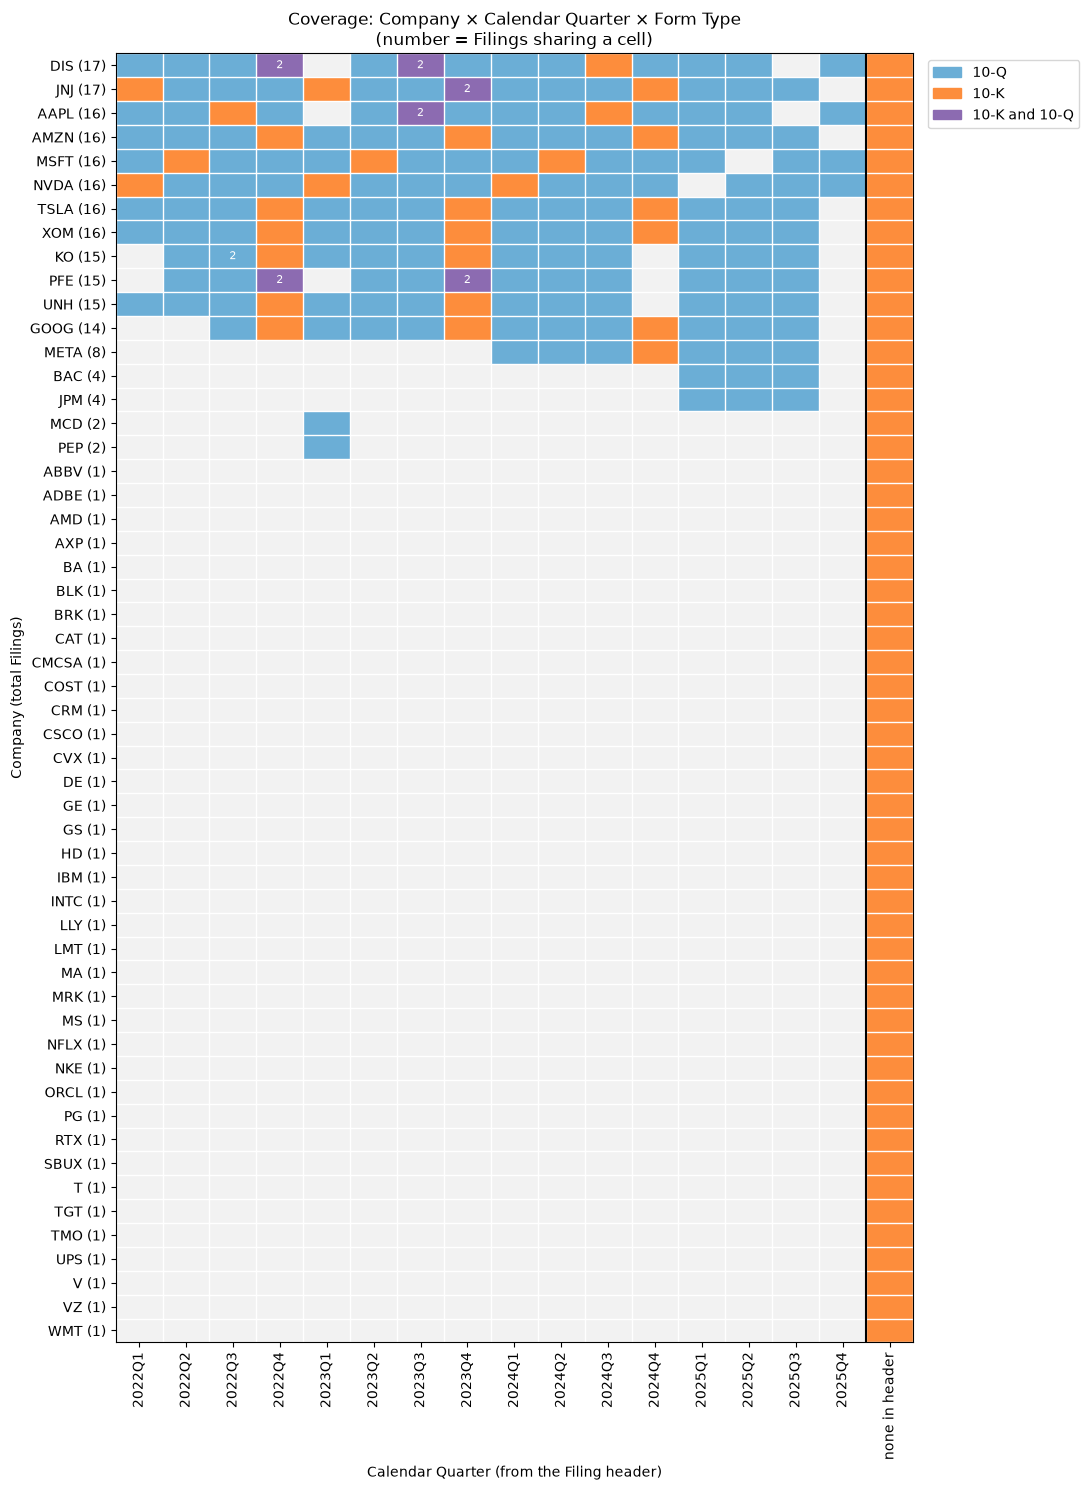

In [4]:
NO_QUARTER = "none in header"

known_quarters = df["calendar_quarter"].dropna()
quarters = [str(q) for q in pd.period_range(known_quarters.min(), known_quarters.max(), freq="Q")]
columns = quarters + [NO_QUARTER]
tickers = list(per_company.index)

# Cell code: 0 = no Filing, 1 = 10-Q only, 2 = 10-K only, 3 = both.
codes = np.zeros((len(tickers), len(columns)), dtype=int)
counts = np.zeros_like(codes)
for f in filings:
    row = tickers.index(f.ticker)
    col = columns.index(f.calendar_quarter or NO_QUARTER)
    codes[row, col] |= 2 if f.form_type == "10-K" else 1
    counts[row, col] += 1

colours = ["#f2f2f2", "#6baed6", "#fd8d3c", "#8c6bb1"]
fig, ax = plt.subplots(figsize=(11, 15))
ax.imshow(codes, cmap=ListedColormap(colours), vmin=0, vmax=3, aspect="auto")
for r, c in zip(*np.nonzero(counts > 1), strict=True):
    ax.text(c, r, counts[r, c], ha="center", va="center", fontsize=8, color="white")

ax.set_xticks(range(len(columns)), columns, rotation=90)
ax.set_yticks(range(len(tickers)), [f"{t} ({per_company.loc[t, 'total']})" for t in tickers])
ax.set_xticks(np.arange(-0.5, len(columns)), minor=True)
ax.set_yticks(np.arange(-0.5, len(tickers)), minor=True)
ax.grid(which="minor", color="white", linewidth=1)
ax.tick_params(which="minor", length=0)
ax.axvline(len(quarters) - 0.5, color="black", linewidth=1.5)
ax.set_xlabel("Calendar Quarter (from the Filing header)")
ax.set_ylabel("Company (total Filings)")
ax.set_title("Coverage: Company × Calendar Quarter × Form Type\n(number = Filings sharing a cell)")
ax.legend(
    handles=[
        Patch(color=colour, label=label)
        for colour, label in zip(colours[1:], ["10-Q", "10-K", "10-K and 10-Q"], strict=True)
    ],
    loc="upper left",
    bbox_to_anchor=(1.01, 1.0),
)
fig.tight_layout()
plt.show()

In [5]:
missing_quarter = df[df["calendar_quarter"].isna()]
shared_cells = int((counts[:, : len(quarters)] > 1).sum())
print(f"Filings with no Calendar Quarter in the header: {len(missing_quarter)}")
print(f"Companies with exactly one Filing: {(per_company['total'] == 1).sum()}")
print(f"Companies with 4 or more Filings: {(per_company['total'] >= 4).sum()}")
print(f"Company × Calendar Quarter cells holding more than one Filing: {shared_cells}")

Filings with no Calendar Quarter in the header: 54
Companies with exactly one Filing: 37
Companies with 4 or more Filings: 15
Company × Calendar Quarter cells holding more than one Filing: 7


**What the grid shows**

- Coverage is very uneven. 12 Companies have 14–17 Filings spread over 2022Q1–2025Q4,
  META has 8, JPM and BAC have 4, MCD and PEP have 2, and the remaining 37 Companies
  have a single 10-K.
- Every Company has exactly one Filing with no Calendar Quarter (or Report Period) in
  its header: its most recent 10-K (filed between 2024 and 2026, plus GE's from 2015).
  For the 37 single-Filing Companies that is their only Filing, so they cannot be
  placed on the time axis from the header alone.
- Several Company × Calendar Quarter cells hold two Filings (e.g. Coca-Cola's two
  2022Q3 Filings), so Calendar Quarter cannot be a unique key.
- Coverage starts in 2022Q1, a year before the brief's "2023–2025".

**So the design does:**

- Treat Company coverage as first-class metadata: classify each Company as a Tracked
  Company (quarterly Filings across years, trend questions answerable) or a Snapshot
  Company (point-in-time only), and have the Answer Call state plainly when coverage
  limits an answer.
- Filter retrieval on Company and Report Period metadata instead of relying on
  similarity alone, so a trend question about a Tracked Company is not crowded out by
  one-off 10-Ks, and a comparison across Snapshot Companies retrieves each of them.
- Derive a Report Period for every Filing whose header lacks one (next analysis), and
  never use Calendar Quarter as a key.

### 1.2 Tracked and Snapshot Companies

A trend question ("How has NVIDIA's revenue changed over the last two years?") needs
a run of consecutive quarters. For each Company the next cell counts the longest run
of consecutive quarter-ends its Filings cover, on the Report Period (a 10-K counts as
its fiscal year's fourth quarter-end). A Company is a **Tracked Company** when that run
is at least eight quarters (two years) and a **Snapshot Company** otherwise.

In [6]:
by_ticker = {}
for f in filings:
    by_ticker.setdefault(f.ticker, []).append(f)

coverage = pd.DataFrame(
    {
        "ticker": ticker,
        "filings": len(fs),
        "10-K": sum(f.form_type == "10-K" for f in fs),
        "10-Q": sum(f.form_type == "10-Q" for f in fs),
        "first report period": min(f.report_period for f in fs),
        "last report period": max(f.report_period for f in fs),
        "consecutive quarters": consecutive_quarters(fs),
        "coverage": fs[0].coverage,
    }
    for ticker, fs in by_ticker.items()
).set_index("ticker")
coverage = coverage.sort_values(["consecutive quarters", "filings"], ascending=False)
print(f"Tracked/Snapshot cut-off: {TRACKED_MIN_QUARTERS} consecutive quarters")
coverage["coverage"].value_counts().to_frame("Companies").T

Tracked/Snapshot cut-off: 8 consecutive quarters


coverage,snapshot,tracked
Companies,41,13


In [7]:
coverage[coverage["filings"] > 1]

,filings,10-K,10-Q,first report period,last report period,consecutive quarters,coverage
ticker,,,,,,,
DIS,17,4,13,2022-01-01,2025-12-27,17,tracked
JNJ,17,5,12,2022-01-02,2025-12-28,17,tracked
AAPL,16,4,12,2022-03-26,2025-12-27,16,tracked
AMZN,16,4,12,2022-03-31,2025-12-31,16,tracked
MSFT,16,4,12,2022-03-31,2025-12-31,16,tracked
NVDA,16,4,12,2022-01-30,2025-10-26,16,tracked
TSLA,16,4,12,2022-03-31,2025-12-31,16,tracked
XOM,16,4,12,2022-03-31,2025-12-31,16,tracked
KO,15,3,12,2022-04-01,2025-09-26,15,tracked


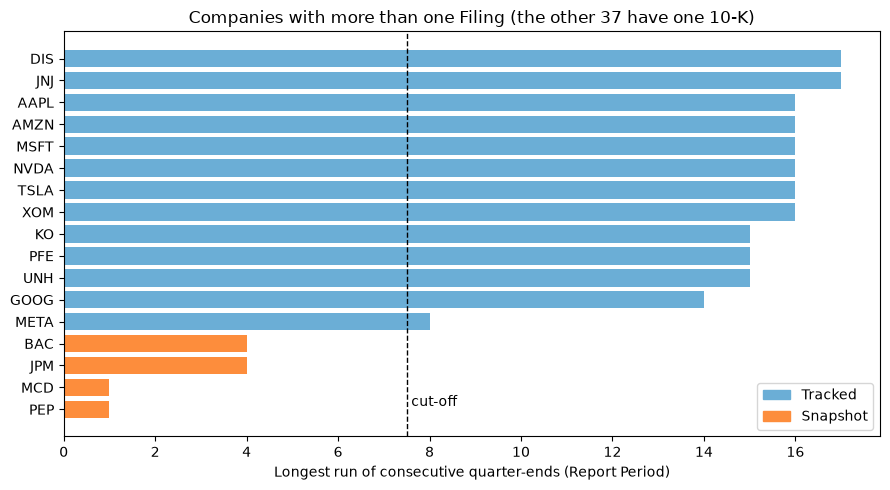

In [8]:
multi = coverage[coverage["filings"] > 1]
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(
    multi.index[::-1],
    multi["consecutive quarters"][::-1],
    color=["#6baed6" if c == "tracked" else "#fd8d3c" for c in multi["coverage"][::-1]],
)
ax.axvline(TRACKED_MIN_QUARTERS - 0.5, color="black", linestyle="--", linewidth=1)
ax.text(TRACKED_MIN_QUARTERS - 0.4, 0, "cut-off", va="bottom")
ax.set_xlabel("Longest run of consecutive quarter-ends (Report Period)")
ax.set_title("Companies with more than one Filing (the other 37 have one 10-K)")
ax.legend(
    handles=[Patch(color="#6baed6", label="Tracked"), Patch(color="#fd8d3c", label="Snapshot")],
    loc="lower right",
)
fig.tight_layout()
plt.show()

**Choosing the cut-off.** The runs fall into clear groups: 12 Companies cover 14–17
consecutive quarters from 2022 to 2025, META covers exactly 8 (2024Q1–2025Q4), BAC
and JPM cover 4, and MCD, PEP and the 37 single-10-K Companies never cover two
quarters in a row. Nothing falls between 4 and 8, so any cut-off from 5 to 8 gives
the same split. Eight is chosen because it is what the Client's own example asks for
("over the last two years") and what a year-over-year comparison of every quarter
needs.

**Borderline Companies:**

- **META (Tracked, 8 quarters):** exactly at the cut-off. Its Filings start in 2024,
  so "the last two years" is answerable but nothing earlier is.
- **BAC and JPM (Snapshot, 4 quarters):** one year of quarters (BAC 2024Q4–2025Q3,
  JPM 2025Q1–2025Q4). Quarter-on-quarter movement within that year is answerable, and
  each Filing carries prior-year comparatives, but a two-year trend is not.
- **MCD and PEP (Snapshot, 2 Filings each):** a 10-Q and a 10-K far apart (MCD
  2023Q1 and FY2024, PEP 2023Q1 and FY2025). Two point-in-time snapshots, not a trend.

### 1.3 Sectors

No Filing carries a Sector, so each Company is mapped to one from a curated
GICS-style reference table (`data/reference/sectors.csv`), which also holds the
Company's SEC SIC code and explains every case where the two disagree.

In [9]:
sectors = pd.DataFrame(load_sector_table()).set_index("ticker")
sector_summary = (
    pd.DataFrame(
        {
            "Companies": sectors.groupby("sector").size(),
            "Tracked": coverage.join(sectors)
            .query("coverage == 'tracked'")
            .groupby("sector")
            .size(),
            "Filings": pd.Series(Counter(f.sector for f in filings)),
        }
    )
    .fillna(0)
    .astype(int)
    .sort_values("Filings", ascending=False)
)
sector_summary["Companies (tickers)"] = sectors.groupby("sector").apply(
    lambda g: ", ".join(sorted(g.index))
)
sector_summary

,Companies,Tracked,Filings,Companies (tickers)
Information Technology,10,3,55,"AAPL, ADBE, AMD, CRM, CSCO, IBM, INTC, MSFT, N..."
Health Care,7,3,51,"ABBV, JNJ, LLY, MRK, PFE, TMO, UNH"
Communication Services,7,3,43,"CMCSA, DIS, GOOG, META, NFLX, T, VZ"
Consumer Discretionary,6,2,37,"AMZN, HD, MCD, NKE, SBUX, TSLA"
Consumer Staples,6,1,21,"COST, KO, PEP, PG, TGT, WMT"
Energy,2,1,17,"CVX, XOM"
Financials,10,0,16,"AXP, BAC, BLK, BRK, GE, GS, JPM, MA, MS, V"
Industrials,6,0,6,"BA, CAT, DE, LMT, RTX, UPS"


In [10]:
disagreements = sectors[~sectors["sic_agrees"]]
print(f"Companies whose SIC code points elsewhere than the GICS-style label: {len(disagreements)}")
with pd.option_context("display.max_colwidth", None):
    display(disagreements[["sector", "industry", "sic_code", "sic_description", "note"]])

Companies whose SIC code points elsewhere than the GICS-style label: 14


,sector,industry,sic_code,sic_description,note
ticker,,,,,
ABBV,Health Care,Biotechnology,2834,Pharmaceutical Preparations,"SIC files AbbVie with the other drug makers (2834); the GICS-style label puts it in Biotechnology. Same sector and same Pharmaceuticals, Biotechnology & Life Sciences group, so AbbVie counts as one of the major pharmaceutical companies alongside JNJ, LLY, MRK and PFE."
BRK,Financials,Financial Services,6331,"Fire, Marine & Casualty Insurance","SIC classes Berkshire by its insurance operations; the GICS-style label treats it as a multi-sector holding company (railroad, utilities, manufacturing and insurance). Same sector, different industry."
COST,Consumer Staples,Consumer Staples Distribution & Retail,5331,Retail-Variety Stores,"SIC has a single Retail division and no staples/discretionary split. The GICS-style label puts general merchandise retailers that mainly sell food and household goods (Costco, Target, Walmart) in Consumer Staples, apart from Amazon and Home Depot in Consumer Discretionary."
DIS,Communication Services,Entertainment,7990,Services-Miscellaneous Amusement & Recreation,"SIC reflects Disney's theme parks (amusement and recreation, a consumer services code); the GICS-style label classes it by its media and streaming business as Entertainment in Communication Services."
GOOG,Communication Services,Interactive Media & Services,7370,"Services-Computer Programming, Data Processing, Etc.",SIC classes Alphabet as a computer services company; the GICS-style label classes it by its advertising-funded search and YouTube business as Interactive Media & Services (moved from Information Technology to Communication Services in 2018).
IBM,Information Technology,IT Services,3570,Computer & office Equipment,"SIC still reflects IBM's hardware history; the GICS-style label classes it by today's software and consulting business as IT Services. Same sector, different industry."
MA,Financials,Financial Services,7389,"Services-Business Services, NEC","SIC classes payment networks as business services; the GICS-style label puts them in Financials (Transaction & Payment Processing Services), where GICS moved them from Information Technology in 2023."
META,Communication Services,Interactive Media & Services,7370,"Services-Computer Programming, Data Processing, Etc.",SIC classes Meta as a computer services company; the GICS-style label classes it by its advertising-funded social media business as Interactive Media & Services in Communication Services.
NFLX,Communication Services,Entertainment,7841,Services-Video Tape Rental,"SIC still files Netflix under video tape rental, from its DVD-by-mail origins; the GICS-style label classes the streaming business as Entertainment in Communication Services."


In [11]:
health_care = sectors[sectors["sector"] == "Health Care"].join(coverage["coverage"])
health_care[["company", "industry", "sic_code", "sic_description", "coverage"]]

,company,industry,sic_code,sic_description,coverage
ticker,,,,,
ABBV,AbbVie Inc,Biotechnology,2834,Pharmaceutical Preparations,snapshot
JNJ,Johnson & Johnson,Pharmaceuticals,2834,Pharmaceutical Preparations,tracked
LLY,Eli Lilly and Company,Pharmaceuticals,2834,Pharmaceutical Preparations,snapshot
MRK,Merck & Co Inc,Pharmaceuticals,2834,Pharmaceutical Preparations,snapshot
PFE,Pfizer Inc,Pharmaceuticals,2834,Pharmaceutical Preparations,tracked
TMO,Thermo Fisher Scientific Inc,Life Sciences Tools & Services,3829,"Measuring & Controlling Devices, NEC",snapshot
UNH,UnitedHealth Group Inc,Health Care Providers & Services,6324,Hospital & Medical Service Plans,tracked


**What the Sector table shows**

- The 54 Companies span eight GICS-style sectors; there is no Materials, Real Estate
  or Utilities Company. Filings are concentrated in Information Technology, Health
  Care and Communication Services because most Tracked Companies sit there. None of
  the 10 Financials Companies is Tracked: bank questions are point-in-time only.
- SIC and the GICS-style label disagree for 14 Companies, for five reasons: SIC
  codes are old (Netflix is "video tape rental", IBM "computer equipment"); SIC
  classifies by activity where GICS classifies by business model (Alphabet and Meta
  as computer services, Disney as amusement parks, UnitedHealth as an insurer, Thermo
  Fisher as an instrument maker); SIC has no staples/discretionary split for
  retailers (Walmart, Costco, Target); GICS has moved Companies since (Visa and
  Mastercard to Financials in 2023); and GICS draws finer industry lines inside the
  same sector (AbbVie as Biotechnology, Berkshire as a multi-sector holding company
  rather than an insurer).
- "The major pharmaceutical companies" resolves to five Companies: JNJ, LLY, MRK, PFE
  (GICS Pharmaceuticals) and ABBV (GICS Biotechnology). All five share SIC 2834.
  UnitedHealth and Thermo Fisher are Health Care but not drug makers, so they stay
  out. Only JNJ and PFE are Tracked; the other three have a single 10-K.
- The GE Filing is classed as Financials because it is GE Capital's report, even
  though the header names General Electric Company (today an Industrials Company).

**So the design does:**

- Carry Sector, industry and the Tracked/Snapshot class on every Filing and chunk.
  Sector-scoped questions filter on Sector or industry metadata, then retrieve per
  Company, instead of hoping similarity finds the right Companies.
- Resolve industry-group phrases with a small rule-based synonym list over the
  table (e.g. "pharmaceutical" → Pharmaceuticals and Biotechnology), keeping query
  parsing before the Answer Call rule-based.
- Tell the Answer Call each Company's coverage class, so a trend question about a
  Snapshot Company is answered as point-in-time with the limit stated, and a sector
  question says which Companies support trends.

## 2. Metadata integrity

Can every Filing be placed on the time axis and identified unambiguously? This
analysis checks the metadata from every angle available: the header, the file name,
the manifest, the source URL and the cover-page sentence ("For the fiscal year ended
..." / "For the quarterly period ended ...").

The Corpus seam resolves each Filing's Report Period from the header, else the date
in the source URL, else the cover-page sentence. It cross-checks every source that is
present and records disagreements as diagnostics on the Filing.

### 2.1 Manifest vs files on disk, and header vs file name

In [12]:
manifest = json.loads((DEFAULT_CORPUS_DIR / "manifest.json").read_text(encoding="utf-8"))
print("Manifest problems:", check_manifest() or "none")
print("Manifest Form Type counts:", manifest["filing_types"])
print("Header Form Type counts:  ", dict(Counter(f.form_type for f in filings)))

FILE_NAME = re.compile(r"^([A-Z]+)_(10K|10Q)_(?:(\d{4}Q[1-4])_)?(\d{4}-\d{2}-\d{2})_full\.txt$")
name_mismatches = []
for f in filings:
    ticker, form, quarter, filed = FILE_NAME.match(f.path.name).groups()
    expected = (f.ticker, f.form_type.replace("-", ""), f.calendar_quarter, str(f.filing_date))
    if (ticker, form, quarter, filed) != expected:
        name_mismatches.append(f.path.name)
print("File names disagreeing with their header (ticker, Form Type, Quarter, Filing Date):")
print("  ", name_mismatches or "none")

Manifest problems: none
Manifest Form Type counts: {'10-K': 89, '10-Q': 157}
Header Form Type counts:   {'10-K': 89, '10-Q': 157}
File names disagreeing with their header (ticker, Form Type, Quarter, Filing Date):
   none


### 2.2 Missing header fields and where each Report Period came from

In [13]:
header_fields = pd.DataFrame(
    {
        "Report Period in header": sum(f.report_period_source == "header" for f in filings),
        "Calendar Quarter in header": sum(f.calendar_quarter is not None for f in filings),
    },
    index=["Filings"],
)
header_fields["Filings in Corpus"] = len(filings)
header_fields

,Report Period in header,Calendar Quarter in header,Filings in Corpus
Filings,192,192,246


In [14]:
sources = pd.crosstab(
    pd.Series([f.report_period_source for f in filings], name="Report Period source"),
    pd.Series([f.form_type for f in filings], name="Form Type"),
    margins=True,
)
sources

Form Type,10-K,10-Q,All
Report Period source,,,
header,35,157,192
text,1,0,1
url,53,0,53
All,89,157,246


In [15]:
# Section diagnostics belong to analysis 4.
diagnostics = [
    (f.filing_id, d.code, d.detail)
    for f in filings
    for d in f.diagnostics
    if not d.code.startswith("section_")
]
print(f"Filings with a Report Period: {sum(f.report_period is not None for f in filings)}")
print(f"Diagnostics (source disagreements, missing cover-page sentence, ...): {len(diagnostics)}")
pd.DataFrame(diagnostics, columns=["filing_id", "code", "detail"])

Filings with a Report Period: 246
Diagnostics (source disagreements, missing cover-page sentence, ...): 0


,filing_id,code,detail


The 54 Filings with no Report Period in the header are exactly the 54 most recent
10-Ks, one per Company. 53 have a dated source URL; the cover-page sentence agrees
with it in every case. For the 192 Filings that do have a header Report Period, the
URL date and the cover-page sentence agree with it too. Two kinds of flattening
quirk had to be handled to find the sentence: the date glued to the phrase
(`endedDecember 31, 2025`) and a table cell between them
(`For the quarterly period ended | Commission file |\nMarch 31, 2025`).

### 2.3 The GE Filing

In [16]:
ge = next(f for f in filings if f.ticker == "GE")
ge_text = ge.path.read_text(encoding="utf-8")
registrant = re.search(r"([A-Z][A-Za-z ]+?)\s*\(Exact name of registrant", ge_text).group(1)
print(f"Header Company:      {ge.company} (CIK {ge.cik})")
print(f"Cover-page registrant: {registrant}")
print(f"Source URL:          {ge.source_url}")
print(f"Report Period:       {ge.report_period} (from {ge.report_period_source})")
print(f"Fiscal Period:       {ge.fiscal_period}, filed {ge.filing_date}")

Header Company:      General Electric Company (CIK 0000040554)
Cover-page registrant: General Electric Capital Corporation
Source URL:          https://www.sec.gov/Archives/edgar/data/40554/000004054515000032/gecc10k2014.htm
Report Period:       2014-12-31 (from text)
Fiscal Period:       FY2014, filed 2015-02-27


The GE Filing is **not** a General Electric Company report. Its header says "General
Electric Company", but the cover page names **General Electric Capital Corporation**
(GE Capital) as the registrant, the document is `gecc10k2014.htm`, and the CIK it is
filed under (0000040554) is GE Capital's EDGAR folder. It is GE Capital's 10-K for
the **fiscal year ended 31 December 2014**, filed on 27 February 2015. Its URL has no
date, so its Report Period comes from the cover-page sentence.

### 2.4 Calendar Quarter clashes

In [17]:
def calendar_quarter_of(d):
    return f"{d.year}Q{(d.month - 1) // 3 + 1}"


inconsistent = [
    f.filing_id
    for f in filings
    if f.calendar_quarter and f.calendar_quarter != calendar_quarter_of(f.report_period)
]
print("Calendar Quarter not the quarter its Report Period ends in:", inconsistent or "none")

by_cell = df.assign(filing=filings).dropna(subset=["calendar_quarter"])
clashes = pd.DataFrame(
    {
        "ticker": f.ticker,
        "calendar_quarter": f.calendar_quarter,
        "form_type": f.form_type,
        "report_period": f.report_period,
        "fiscal_period": f.fiscal_period,
        "filing_id": f.filing_id,
    }
    for _, group in by_cell.groupby(["ticker", "calendar_quarter"])
    if len(group) > 1
    for f in group["filing"]
)
clashes

Calendar Quarter not the quarter its Report Period ends in: none


,ticker,calendar_quarter,form_type,report_period,fiscal_period,filing_id
0,AAPL,2023Q3,10-K,2023-09-30,FY2023,AAPL_10-K_2023-09-30
1,AAPL,2023Q3,10-Q,2023-07-01,Q3 FY2023,AAPL_10-Q_2023-07-01
2,DIS,2022Q4,10-K,2022-10-01,FY2022,DIS_10-K_2022-10-01
3,DIS,2022Q4,10-Q,2022-12-31,Q1 FY2023,DIS_10-Q_2022-12-31
4,DIS,2023Q3,10-K,2023-09-30,FY2023,DIS_10-K_2023-09-30
5,DIS,2023Q3,10-Q,2023-07-01,Q3 FY2023,DIS_10-Q_2023-07-01
6,JNJ,2023Q4,10-K,2023-12-31,FY2023,JNJ_10-K_2023-12-31
7,JNJ,2023Q4,10-Q,2023-10-01,Q3 FY2023,JNJ_10-Q_2023-10-01
8,KO,2022Q3,10-Q,2022-07-01,Q2 FY2022,KO_10-Q_2022-07-01
9,KO,2022Q3,10-Q,2022-09-30,Q3 FY2022,KO_10-Q_2022-09-30


In [18]:
ids = [f.filing_id for f in filings]
cells = by_cell.groupby(["ticker", "calendar_quarter"]).ngroups
print(f"Company × Calendar Quarter cells with a Filing: {cells}")
print(f"Filings with a Calendar Quarter:                {len(by_cell)}")
print(f"Distinct Filing identifiers:                   {len(set(ids))} of {len(ids)}")

Company × Calendar Quarter cells with a Filing: 185
Filings with a Calendar Quarter:                192
Distinct Filing identifiers:                   246 of 246


Every Calendar Quarter label is correct by its own definition (the calendar quarter
in which the Report Period ends), yet seven Company × Calendar Quarter cells hold two
Filings. All seven come from 52/53-week fiscal calendars whose periods end a day or
two into the next calendar quarter. Coca-Cola's second quarter of 2022 ended on
1 July, so it shares 2022Q3 with its third quarter (30 September). Apple's and
Disney's third quarters of 2023 also ended on 1 July. Disney's FY2022 and Pfizer's
and J&J's third quarters ended on 1–2 October. The identifier
`ticker_FormType_ReportPeriod` keeps all 246 Filings distinct.

### 2.5 CIK and Company name consistency

In [19]:
ciks_per_ticker = df.assign(cik=[f.cik for f in filings]).groupby("ticker")["cik"].nunique()
tickers_per_cik = df.assign(cik=[f.cik for f in filings]).groupby("cik")["ticker"].nunique()
names_per_ticker = df.groupby("ticker")["company"].nunique()
url_not_under_cik = [f.filing_id for f in filings if f"/data/{int(f.cik)}/" not in f.source_url]
print(f"Tickers with more than one CIK:  {(ciks_per_ticker > 1).sum()}")
print(f"CIKs with more than one ticker:  {(tickers_per_cik > 1).sum()}")
print(f"Tickers with more than one name: {(names_per_ticker > 1).sum()}")
print(f"Filings whose URL is not under their CIK: {url_not_under_cik or 'none'}")

Tickers with more than one CIK:  0
CIKs with more than one ticker:  0
Tickers with more than one name: 0
Filings whose URL is not under their CIK: none


### 2.6 Fiscal year ends and Fiscal Periods

Each Company's fiscal year end is derived from its 10-K Report Periods. A period end
within the first seven days of a month counts as the end of the previous month, so
52/53-week years (Deere's 2 November, J&J's 2 January) map to the right month. Each
Filing's Fiscal Period is then counted from that month, and the fiscal year is named
after the calendar year in which it ends.

In [20]:
fiscal_year_ends = (
    pd.Series({f.ticker: f.fiscal_year_end_month for f in filings}, name="fiscal year end month")
    .map(lambda m: pd.Timestamp(2000, m, 1).strftime("%B"))
    .rename_axis("ticker")
)
fiscal_year_ends.value_counts().to_frame("Companies").T

fiscal year end month,December,January,September,June,May,November,August,July,October
Companies,37,5,4,2,2,1,1,1,1


In [21]:
fiscal_year_ends[fiscal_year_ends != "December"].to_frame().T

ticker,AAPL,ADBE,COST,CRM,CSCO,DE,DIS,HD,MSFT,NKE,NVDA,ORCL,PG,SBUX,TGT,V,WMT
fiscal year end month,September,November,August,January,July,October,September,January,June,May,January,May,June,September,January,September,January


In [22]:
example = next(f for f in filings if f.ticker == "NVDA" and str(f.report_period) == "2025-07-27")
print(f"{example.filing_id}: {example.fiscal_period}")
print(f"Filings without a Fiscal Period: {sum(f.fiscal_period is None for f in filings)}")

NVDA_10-Q_2025-07-27: Q2 FY2026
Filings without a Fiscal Period: 0


17 of 54 Companies do not have a December year end. The Fiscal Period rule reproduces
each Company's own label where we checked it (NVIDIA's quarter ending 27 July 2025 is
Q2 FY2026; Apple, Microsoft, Walmart and Salesforce match their reports). It does
**not** match retailers that name a fiscal year after the year it starts in: Home
Depot calls the year ended 2 February 2025 "fiscal 2024", and Target likewise, while
the rule labels it FY2025. Both are Snapshot Companies with one 10-K each, and the
Fiscal Period is a secondary label, so this is recorded rather than special-cased.

### 2.7 Filings outside the brief's "2023–2025" window

In [23]:
out_of_window = sorted(
    (f for f in filings if not 2023 <= f.report_period.year <= 2025),
    key=lambda f: (f.report_period, f.ticker),
)
print(f"Filings with a Report Period outside 2023–2025: {len(out_of_window)}")
pd.DataFrame(
    {
        "ticker": f.ticker,
        "form_type": f.form_type,
        "report_period": f.report_period,
        "fiscal_period": f.fiscal_period,
        "filing_date": f.filing_date,
    }
    for f in out_of_window
).groupby("ticker").agg(
    filings=("form_type", "size"),
    first=("report_period", "min"),
    last=("report_period", "max"),
    forms=("form_type", lambda s: ", ".join(f"{n} {t}" for t, n in Counter(s).items())),
)

Filings with a Report Period outside 2023–2025: 48


,filings,first,last,forms
ticker,,,,
AAPL,4,2022-03-26,2022-12-31,"3 10-Q, 1 10-K"
AMZN,4,2022-03-31,2022-12-31,"3 10-Q, 1 10-K"
DIS,5,2022-01-01,2022-12-31,"4 10-Q, 1 10-K"
GE,1,2014-12-31,2014-12-31,1 10-K
GOOG,2,2022-09-30,2022-12-31,"1 10-Q, 1 10-K"
JNJ,4,2022-01-02,2022-10-02,"1 10-K, 3 10-Q"
KO,4,2022-04-01,2022-12-31,"3 10-Q, 1 10-K"
MSFT,4,2022-03-31,2022-12-31,"3 10-Q, 1 10-K"
NVDA,4,2022-01-30,2022-10-30,"1 10-K, 3 10-Q"


In [24]:
filed_after = [f for f in filings if f.filing_date.year > 2025]
print(f"Filings inside the window by Report Period but filed in 2026: {len(filed_after)}")
print("By Form Type:", dict(Counter(f.form_type for f in filed_after)))

Filings inside the window by Report Period but filed in 2026: 27
By Form Type: {'10-Q': 3, '10-K': 24}


**What the integrity checks show**

- The metadata is internally consistent: the manifest matches the files on disk, every
  file name agrees with its header, each ticker has one CIK and one name, and every
  source URL sits under the Filing's CIK.
- Every Filing now has a Report Period: 192 from the header, 53 from the source URL
  and 1 (GE Capital) from the cover-page sentence. Where more than one source exists
  they agree, so there are no diagnostics to review by hand.
- The "GE" Filing is GE Capital's FY2014 10-K, filed in 2015, under GE's ticker.
- Seven Company × Calendar Quarter cells hold two Filings, all caused by 52/53-week
  fiscal calendars. The identifier `ticker_FormType_ReportPeriod` is unique.
- 17 Companies have a non-December fiscal year end.
- 48 Filings have a Report Period outside 2023–2025: GE Capital's FY2014 10-K and 47
  Filings from 12 Companies in 2022 (including J&J's FY2021 10-K, whose year
  ended 2 January 2022). A further 27 Filings fall inside the window but were filed
  in 2026: 24 FY2025 10-Ks and 3 10-Qs for quarters ending in December 2025.

**So the design does:**

- Use the Report Period as the time axis and `ticker_FormType_ReportPeriod` as the
  Filing key everywhere (chunk metadata, citations, Financial Facts). Never key on
  Calendar Quarter or Filing Date.
- Keep the Report Period source on every Filing and keep cross-checking it, so a new
  Filing whose sources disagree is surfaced, not silently trusted.
- Show both the Report Period and the Fiscal Period in citations ("NVIDIA 10-Q, Q2
  FY2026, period ended 2025-07-27"), and resolve relative questions ("last two
  years", "latest") on Report Period.
- Keep all 48 out-of-window Filings, but flag GE Capital's FY2014 10-K as stale and
  attribute it to GE Capital, not General Electric, in any answer that uses it.

## 3. Text anatomy

What is each Filing actually made of? Every character of the raw body (the text
after the header) is put in one of five classes:

- **XBRL noise**: the machine-readable residue in front of the cover page, which the
  Corpus seam removes (`Filing.xbrl_noise_chars`).
- **TOC**: the table of contents the seam locates (`Filing.toc`).
- **Exhibits and signatures**: exhibit-index rows ("31.1 | Certification of ...") and
  signature lines ("/s/ ...", "SIGNATURES", "duly caused this report to be signed").
- **Flattened tables**: any other line made of `|`-separated cells, the remains of
  HTML tables. A line counts only if none of its cells is longer than 500
  characters: some Filings glue whole pages of prose into one line around a page
  footer such as "Apple Inc. | 2024 Form 10-K | 20", and that prose is not a table.
- **Prose**: everything else.

The last three are line-level heuristics written for this analysis, not part of the
core package; they are good enough to size cleaning priorities, not to cut text.

In [25]:
EXHIBIT_ROW = re.compile(
    r"^\s*\|?\s*(?:\d{1,3}(?:\.[0-9A-Z]{1,4}){1,2}|10[14])\s*[*†‡#+^]*\s*(?:\(\w\))?\s*\|"
)
SIGNATURE_LINE = re.compile(
    r"/s/|^\s*SIGNATURES?\s*$|duly caused this report to be signed", re.IGNORECASE
)
RUNNING_HEADER = re.compile(r"Table of Contents", re.IGNORECASE)
MAX_TABLE_CELL = 500
CLASSES = ["XBRL noise", "TOC", "Exhibits and signatures", "Flattened tables", "Prose"]


def anatomy(filing):
    """Characters of the raw body in each class."""
    chars = dict.fromkeys(CLASSES, 0)
    chars["XBRL noise"] = filing.xbrl_noise_chars
    toc_start, toc_end = (filing.toc.start, filing.toc.end) if filing.toc else (0, 0)
    pos = 0
    for line in filing.body.split("\n"):
        size = len(line) + 1
        if toc_start <= pos < toc_end:
            chars["TOC"] += size
        elif EXHIBIT_ROW.match(line) or SIGNATURE_LINE.search(line):
            chars["Exhibits and signatures"] += size
        elif "|" in line and max(len(cell) for cell in line.split("|")) <= MAX_TABLE_CELL:
            chars["Flattened tables"] += size
        else:
            chars["Prose"] += size
        pos += size
    return chars


def running_headers(filing):
    """'Table of Contents' page headers left in the text outside the TOC itself."""
    toc_text = filing.body[filing.toc.start : filing.toc.end] if filing.toc else ""
    return len(RUNNING_HEADER.findall(filing.body)) - len(RUNNING_HEADER.findall(toc_text))


anat = pd.DataFrame(
    {
        "ticker": f.ticker,
        "form_type": f.form_type,
        "file": f.path.name,
        "raw_chars": f.xbrl_noise_chars + len(f.body),
        "has_toc": f.toc is not None,
        "running_headers": running_headers(f),
        "longest_line": max(len(line) for line in f.body.split("\n")),
        **anatomy(f),
    }
    for f in filings
)
assert (anat[CLASSES].sum(axis=1) == anat["raw_chars"] + 1).all()  # +1: the final newline


def shares(frame):
    """Character-weighted share of each class, in percent."""
    return (frame[CLASSES].sum() / frame[CLASSES].sum().sum() * 100).round(1)


by_form = pd.DataFrame(
    {
        "Corpus": shares(anat),
        "10-K": shares(anat[anat["form_type"] == "10-K"]),
        "10-Q": shares(anat[anat["form_type"] == "10-Q"]),
    }
).T
by_form

,XBRL noise,TOC,Exhibits and signatures,Flattened tables,Prose
Corpus,13.6,0.4,2.6,19.7,63.7
10-K,11.6,0.3,3.8,16.5,67.7
10-Q,16.2,0.5,1.1,23.5,58.7


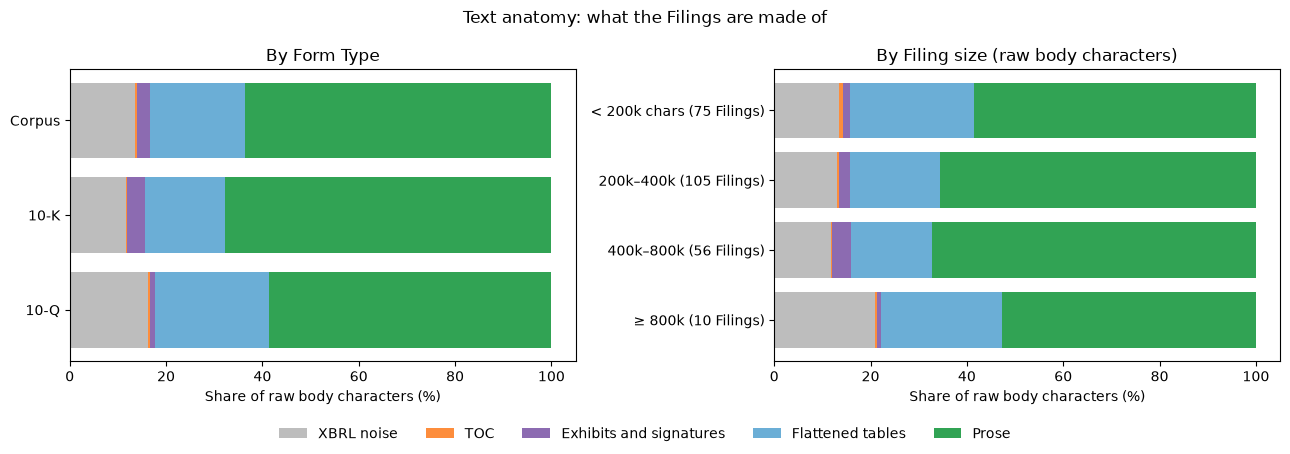

,XBRL noise,TOC,Exhibits and signatures,Flattened tables,Prose,Filings
size_bin,,,,,,
< 200k chars,13.5,0.7,1.4,25.7,58.6,75
200k–400k,13.1,0.4,2.2,18.7,65.6,105
400k–800k,11.7,0.3,4.0,16.7,67.2,56
≥ 800k,21.0,0.3,0.8,25.2,52.7,10


In [26]:
size_bins = [0, 200_000, 400_000, 800_000, float("inf")]
size_labels = ["< 200k chars", "200k–400k", "400k–800k", "≥ 800k"]
anat["size_bin"] = pd.cut(anat["raw_chars"], size_bins, labels=size_labels, right=False)
by_size = anat.groupby("size_bin", observed=True)[CLASSES].sum()
by_size = by_size.div(by_size.sum(axis=1), axis=0) * 100
filings_per_bin = anat["size_bin"].value_counts().reindex(size_labels)

class_colours = ["#bdbdbd", "#fd8d3c", "#8c6bb1", "#6baed6", "#31a354"]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True)
for ax, frame, title, ylabels in [
    (ax1, by_form, "By Form Type", by_form.index),
    (
        ax2,
        by_size,
        "By Filing size (raw body characters)",
        [f"{b} ({filings_per_bin[b]} Filings)" for b in by_size.index],
    ),
]:
    left = np.zeros(len(frame))
    for cls, colour in zip(CLASSES, class_colours, strict=True):
        ax.barh(range(len(frame)), frame[cls], left=left, color=colour, label=cls)
        left += frame[cls].to_numpy()
    ax.set_yticks(range(len(frame)), ylabels)
    ax.invert_yaxis()
    ax.set_title(title)
    ax.set_xlabel("Share of raw body characters (%)")
fig.legend(*ax1.get_legend_handles_labels(), loc="lower center", ncol=5, frameon=False)
fig.suptitle("Text anatomy: what the Filings are made of")
fig.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

by_size.round(1).assign(Filings=filings_per_bin)

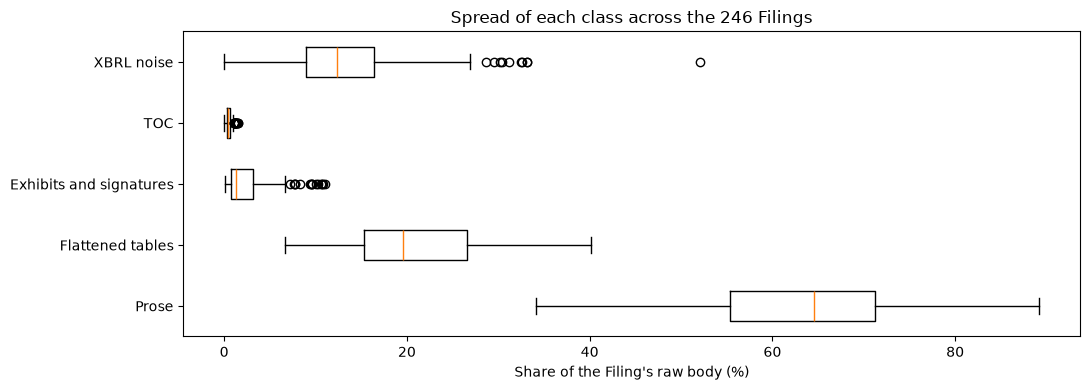

,file,raw_chars,XBRL noise %,TOC %,Exhibits and signatures %,Flattened tables %,Prose %
84,IBM_10K_2025-02-25_full.txt,222965,52.1,0.6,1.2,12.0,34.1
38,BAC_10Q_2025Q2_2025-07-31_full.txt,831442,33.1,0.3,0.3,31.9,34.3
39,BAC_10Q_2025Q3_2025-10-31_full.txt,833401,33.1,0.3,0.3,32.0,34.3
101,JNJ_10Q_2025Q2_2025-07-24_full.txt,305834,32.6,0.4,0.4,20.0,46.6
102,JNJ_10Q_2025Q3_2025-10-22_full.txt,311308,32.5,0.4,0.3,20.0,46.8
37,BAC_10Q_2025Q1_2025-04-30_full.txt,715232,31.2,0.4,0.5,31.4,36.6
98,JNJ_10Q_2024Q2_2024-07-25_full.txt,312509,30.4,0.4,0.4,21.2,47.7
99,JNJ_10Q_2024Q3_2024-10-23_full.txt,316057,30.2,0.4,0.4,19.9,49.1


In [27]:
per_filing = anat.assign(
    **{f"{c} %": (anat[c] / anat["raw_chars"] * 100).round(1) for c in CLASSES}
)
pct = [f"{c} %" for c in CLASSES]
fig, ax = plt.subplots(figsize=(11, 4))
ax.boxplot([per_filing[c] for c in pct], orientation="horizontal", tick_labels=CLASSES)
ax.invert_yaxis()
ax.set_xlabel("Share of the Filing's raw body (%)")
ax.set_title("Spread of each class across the 246 Filings")
fig.tight_layout()
plt.show()

per_filing.sort_values("XBRL noise %", ascending=False)[["file", "raw_chars", *pct]].head(8)

In [28]:
print(f"XBRL noise removed: {anat['XBRL noise'].sum() / 1e6:.1f}M characters in total")
print(
    "Filings where XBRL noise is over 20% of the raw body: "
    f"{(per_filing['XBRL noise %'] > 20).sum()}"
)
print(f"Filings without a table of contents: {(~anat['has_toc']).sum()}")
print(", ".join(anat.loc[~anat["has_toc"], "file"]))
print(
    "Filings with 'Table of Contents' running page headers left in the text: "
    f"{(anat['running_headers'] > 0).sum()} "
    f"({anat['running_headers'].sum()} headers in total)"
)
print(
    "Filings with a single line over 20,000 characters: "
    f"{(anat['longest_line'] > 20_000).sum()} "
    f"(longest: {anat['longest_line'].max():,} characters, "
    f"{anat.loc[anat['longest_line'].idxmax(), 'file']})"
)

XBRL noise removed: 11.1M characters in total
Filings where XBRL noise is over 20% of the raw body: 31
Filings without a table of contents: 9
DIS_10Q_2022Q1_2022-02-09_full.txt, DIS_10Q_2022Q2_2022-05-11_full.txt, DIS_10Q_2022Q3_2022-08-10_full.txt, DIS_10Q_2022Q4_2023-02-08_full.txt, DIS_10Q_2023Q2_2023-05-10_full.txt, DIS_10Q_2023Q3_2023-08-09_full.txt, DIS_10Q_2023Q4_2024-02-07_full.txt, DIS_10Q_2024Q1_2024-05-07_full.txt, DIS_10Q_2024Q2_2024-08-07_full.txt
Filings with 'Table of Contents' running page headers left in the text: 204 (7813 headers in total)
Filings with a single line over 20,000 characters: 135 (longest: 287,855 characters, META_10K_2024Q4_2025-01-30_full.txt)


**What the anatomy shows**

- XBRL noise is 13.6% of all raw text (11.1M characters), more in 10-Qs (16%) than
  10-Ks (12%), over 20% in 31 Filings and 52% in IBM's 10-K. It is pure machine
  residue (context IDs, taxonomy URLs, hidden facts) glued in front of the cover
  page. The Corpus seam strips it, and a Corpus-level test checks that no cleaned
  body contains an XBRL signature.
- Flattened tables are about a fifth of the text (24% in 10-Qs, a quarter of the
  largest Filings). They hold most of the numbers the Client will ask about, but as
  rows of `|`-separated cells, so a value cut away from its row and column labels
  means nothing.
- The TOC is small (under 1%) but dangerous: its rows repeat every Item heading.
  The seam locates it in all but nine Filings (Disney 10-Qs before 2025, which have
  none), always in the first tenth of the body.
- Exhibit indexes and signatures are about 3% (4% of 10-Ks) and carry no business
  content.
- Line breaks are not paragraph breaks. 135 Filings have a single line over 20,000
  characters (META's longest is 287,855): whole pages of prose glued together, with
  page footers ("Apple Inc. | 2024 Form 10-K | 20") and "Table of Contents" running
  headers (7,813 of them, in 204 Filings) embedded mid-line.

**So the design does:**

- Index only the cleaned body: XBRL noise never reaches a chunk or a prompt.
- Skip the TOC span in Section detection (next analysis) and leave it out of the
  index, so a TOC row like "Item 1A. | Risk Factors | 5" is never retrieved as if it
  were the Risk Factors.
- Leave exhibit indexes and signatures out of the index.
- Chunk tables as whole tables (or row groups that repeat the table's header rows),
  never splitting a row from its labels, and tag them as table chunks so the Answer
  Call knows it is reading a table. Their numbers are also the input to the Financial
  Facts experiment (analysis 7).
- Split prose on sentence boundaries within a token budget, not on line breaks, and
  strip running page headers and page footers before chunking so they do not pollute
  chunk text and embeddings.

## 4. Section and Item detection

Can Filings be addressed by Section? The Corpus seam splits each cleaned body at its
Item headings, skipping the TOC. Each Section carries a standard, form-independent
name and the Item label the Filing used, so 10-K Item 7 and 10-Q Part I, Item 2 are
both **MD&A**, while a question about "Item 7" can still filter on the label. Text
before the first heading (cover page, TOC, forward-looking statements) is kept as
an **Unsectioned** Section, so the Sections of a Filing add up to its whole body.

A heading is an Item number followed by the start of the Item's official title
("Item 1A. Risk Factors"). Flattening glues headings into running text, so the
splitter cannot rely on line starts. It rejects three look-alikes:

- **cross-references**, which cite an Item mid-sentence ("see Part II, Item 7,
  “Management's Discussion…”"): a heading is never preceded by a lower-case word, a
  comma or an opening quote, unless that word ends a "Table of Contents" page header;
- **TOC rows**, by searching only after the TOC;
- **cross-reference index rows** near the end of some 10-Ks ("Item 1A | Risk Factors |
  Page28"): runs of five or more short table rows naming Items.

Items are searched for in form order first, then any still missing anywhere after
the TOC, because some Filings reorder them. A required Section that cannot be found
is recorded as a `section_not_found` diagnostic on the Filing.

In [29]:
section_rows = pd.DataFrame(
    {
        "file": f.path.name,
        "ticker": f.ticker,
        "form_type": f.form_type,
        "section": s.name,
        "item": s.item,
        "chars": len(s.text),
        "share": len(s.text) / len(f.body),
    }
    for f in filings
    for s in f.sections
)
items = section_rows.dropna(subset=["item"])
mapping = (
    items.groupby(["form_type", "item", "section"], sort=False)
    .size()
    .rename("Filings")
    .reset_index()
)
mapping["order"] = (
    mapping["item"]
    .str.extract(r"(\d+)([A-C]?)$")
    .apply(lambda m: int(m[0]) * 10 + (ord(m[1]) - 64 if m[1] else 0), axis=1)
    + mapping["item"].str.startswith("Part II").astype(int) * 1000
)
mapping.sort_values(["form_type", "order"]).drop(columns="order").set_index(["form_type", "item"])

section  Filings
form_type item                                              
10-K      Item 1                           Business       86
          Item 1A                      Risk Factors       86
          Item 1B                             Other       82
          Item 1C                     Cybersecurity       69
          Item 2                              Other       84
          Item 3                  Legal Proceedings       86
          Item 4                              Other       82
          Item 5                              Other       85
          Item 6                              Other       78
          Item 7                               MD&A       85
          Item 7A                       Market Risk       86
          Item 8               Financial Statements       85
          Item 9                              Other       85
          Item 9A           Controls and Procedures       86
          Item 9B                             Other       85
          Item 9C                             Other       82
          Item 10                             Other       83
          Item 11                             Other       83
          Item 12                             Other       83
          Item 13                             Other       83
          Item 14                             Other       85
          Item 15                             Other       86
          Item 16                             Other       79
10-Q      Part I, Item 1       Financial Statements      154
          Part I, Item 2                       MD&A      154
          Part I, Item 3                Market Risk      157
          Part I, Item 4    Controls and Procedures      157
          Part II, Item 1         Legal Proceedings      157
          Part II, Item 1A             Risk Factors      133
          Part II, Item 2                     Other      144
          Part II, Item 3                     Other       39
          Part II, Item 4                     Other       39
          Part II, Item 5                     Other      112
          Part II, Item 6                     Other      157

In [30]:
REQUIRED = {
    "10-K": [
        "Business",
        "Risk Factors",
        "Legal Proceedings",
        "MD&A",
        "Market Risk",
        "Financial Statements",
        "Controls and Procedures",
        "Cybersecurity",
    ],
    "10-Q": [
        "Financial Statements",
        "MD&A",
        "Market Risk",
        "Controls and Procedures",
        "Legal Proceedings",
        "Risk Factors",
    ],
}
found = items.groupby(["form_type", "section"])["file"].nunique()
filings_per_form = Counter(f.form_type for f in filings)
detection = pd.DataFrame(
    {
        form: {
            name: f"{found.get((form, name), 0)}/{filings_per_form[form]} "
            f"({found.get((form, name), 0) / filings_per_form[form]:.0%})"
            for name in REQUIRED[form]
        }
        for form in ["10-K", "10-Q"]
    }
).fillna("–")
detection

,10-K,10-Q
Business,86/89 (97%),–
Risk Factors,86/89 (97%),133/157 (85%)
Legal Proceedings,86/89 (97%),157/157 (100%)
MD&A,85/89 (96%),154/157 (98%)
Market Risk,86/89 (97%),157/157 (100%)
Financial Statements,85/89 (96%),154/157 (98%)
Controls and Procedures,86/89 (97%),157/157 (100%)
Cybersecurity,69/89 (78%),–


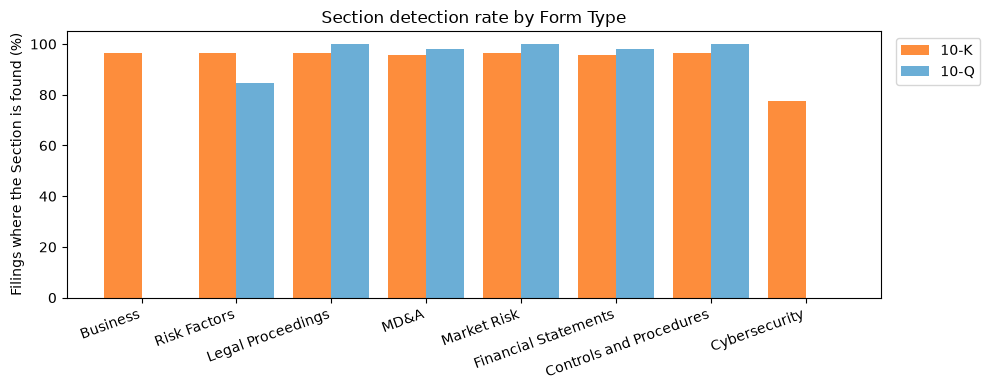

In [31]:
fig, ax = plt.subplots(figsize=(10, 4))
names = REQUIRED["10-K"]
x = np.arange(len(names))
for offset, form, colour in [(-0.2, "10-K", "#fd8d3c"), (0.2, "10-Q", "#6baed6")]:
    rates = [
        found.get((form, n), 0) / filings_per_form[form] * 100 if n in REQUIRED[form] else 0
        for n in names
    ]
    ax.bar(x + offset, rates, width=0.4, color=colour, label=form)
ax.set_xticks(x, names, rotation=20, ha="right")
ax.set_ylabel("Filings where the Section is found (%)")
ax.set_ylim(0, 105)
ax.set_title("Section detection rate by Form Type")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
fig.tight_layout()
plt.show()

### 4.1 Every failure, by name

In [32]:
failures = pd.DataFrame(
    {"file": f.path.name, "form_type": f.form_type, "missing": d.detail}
    for f in filings
    for d in f.diagnostics
    if d.code == "section_not_found"
)
print(f"section_not_found diagnostics: {len(failures)} in {failures['file'].nunique()} Filings")
failures.groupby(["file", "form_type"])["missing"].agg("; ".join).to_frame()

section_not_found diagnostics: 53 in 32 Filings


,,missing
file,form_type,
BAC_10K_2025-02-25_full.txt,10-K,MD&A (Item 7)
CMCSA_10K_2026-02-03_full.txt,10-K,Financial Statements (Item 8)
INTC_10K_2026-01-23_full.txt,10-K,Business (Item 1); Risk Factors (Item 1A); Leg...
JNJ_10Q_2022Q2_2022-04-29_full.txt,10-Q,"Risk Factors (Part II, Item 1A)"
JNJ_10Q_2022Q3_2022-07-29_full.txt,10-Q,"Risk Factors (Part II, Item 1A)"
JNJ_10Q_2022Q4_2022-10-27_full.txt,10-Q,"Risk Factors (Part II, Item 1A)"
JNJ_10Q_2023Q2_2023-04-28_full.txt,10-Q,"Risk Factors (Part II, Item 1A)"
JNJ_10Q_2023Q3_2023-07-31_full.txt,10-Q,"Risk Factors (Part II, Item 1A)"
JNJ_10Q_2023Q4_2023-10-27_full.txt,10-Q,"Risk Factors (Part II, Item 1A)"


Reading each failing Filing shows why:

- **Morgan Stanley, Intel, McDonald's (10-K):** no "Item N" headings in the body at
  all. They use their own headings, mapped to Items in the TOC (Morgan Stanley) or in
  a cross-reference index at the end (Intel, McDonald's). The whole body after the
  TOC is Unsectioned.
- **JPMorgan (10-Q × 3):** the same pattern in its 10-Qs: MD&A and the financial
  statements run under JPMorgan's own headings; only Part II has Item headings.
- **Bank of America (10-K) and Comcast (10-K):** the Company name sits between the
  label and the title ("Item 7. Bank of America Corporation and Subsidiaries /
  Management's Discussion…", "Item 8: Comcast Corporation Financial Statements…").
  Their MD&A and financial statements stay inside the previous Item.
- **J&J and ExxonMobil (10-Q × 24):** not a detection failure. Their 10-Qs have no
  Part II, Item 1A at all; both rely on the risk factors in their 10-K.

Cybersecurity (Item 1C) only became required for fiscal years ending on or after
15 December 2023, so its absence from earlier 10-Ks is not reported as a failure.

### 4.2 Section lengths, stubs and coverage

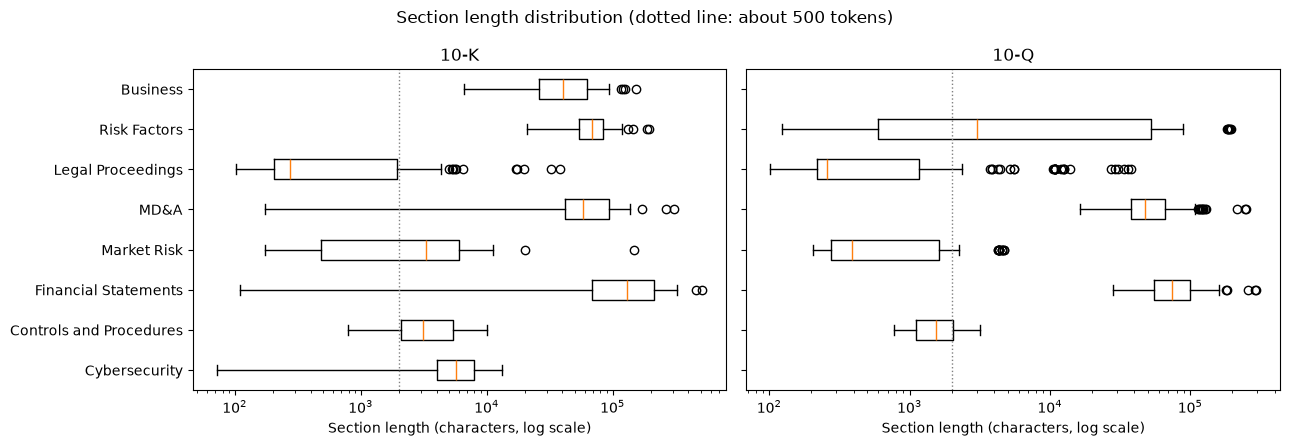

count    min    10%     50%     90%     max
form_type section                                                             
10-K      Business                    86   6638  13558   40290   82224  153071
          Controls and Procedures     86    793   1418    3106    7827    9985
          Cybersecurity               69     72   3291    5719    9132   13199
          Financial Statements        85    111    206  130948  255968  513246
          Legal Proceedings           86    102    159     276    5335   38463
          MD&A                        85    175  16263   57995  126726  307569
          Market Risk                 86    173    295    3288    7533  146561
          Risk Factors                86  20981  37922   69147  108594  195330
10-Q      Controls and Procedures    157    780   1020    1532    2255    3189
          Financial Statements       154  28206  36671   73699  144233  292973
          Legal Proceedings          157    102    135     260   10771   37854
          MD&A                       154  16298  29692   47565  106621  248043
          Market Risk                157    204    227     391    2076    4699
          Risk Factors               133    123    388    3015   72126  194389

In [33]:
named = items[items["section"] != "Other"]
order = REQUIRED["10-K"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, form in zip(axes, ["10-K", "10-Q"], strict=True):
    present = [n for n in order if n in REQUIRED[form]]
    data = [named[(named["form_type"] == form) & (named["section"] == n)]["chars"] for n in present]
    ax.boxplot(data, positions=[order.index(n) for n in present], orientation="horizontal")
    ax.set_xscale("log")
    ax.axvline(2_000, color="grey", linestyle=":", linewidth=1)
    ax.set_title(form)
    ax.set_xlabel("Section length (characters, log scale)")
axes[0].set_yticks(range(len(order)), order)
axes[0].invert_yaxis()
fig.suptitle("Section length distribution (dotted line: about 500 tokens)")
fig.tight_layout()
plt.show()

named.groupby(["form_type", "section"])["chars"].describe(percentiles=[0.1, 0.5, 0.9]).astype(int)[
    ["count", "min", "10%", "50%", "90%", "max"]
]

In [34]:
POINTER = re.compile(
    r"refer to|see |incorporated (?:herein )?by reference|no material changes|"
    r"is (?:included|presented|set forth) (?:in|under)|not applicable|^\W*none",
    re.IGNORECASE,
)
STUB_CHARS = 1_000
stub_rows = named[named["chars"] < STUB_CHARS].copy()
texts = {(f.path.name, s.item): s.text for f in filings for s in f.sections if s.item is not None}
stub_rows["points_elsewhere"] = [
    bool(POINTER.search(texts[(r.file, r.item)])) for r in stub_rows.itertuples()
]
stubs = (
    stub_rows.groupby(["form_type", "section"])
    .agg(stubs=("file", "size"), pointing_elsewhere=("points_elsewhere", "sum"))
    .join(named.groupby(["form_type", "section"]).size().rename("found"))
)
stubs["stub share"] = (stubs["stubs"] / stubs["found"] * 100).round(0).astype(int).astype(str) + "%"
stubs

stubs  pointing_elsewhere  found stub share
form_type section                                                             
10-K      Controls and Procedures      2                   1     86         2%
          Cybersecurity                4                   4     69         6%
          Financial Statements        20                  19     85        24%
          Legal Proceedings           56                  54     86        65%
          MD&A                         8                   3     85         9%
          Market Risk                 26                  18     86        30%
10-Q      Controls and Procedures     12                   0    157         8%
          Legal Proceedings          113                 101    157        72%
          Market Risk                104                  82    157        66%
          Risk Factors                52                  31    133        39%

In [35]:
for file, item in [
    ("JPM_10K_2026-02-13_full.txt", "Item 7"),
    ("AMZN_10K_2024Q4_2025-02-07_full.txt", "Item 3"),
    ("DIS_10K_2025-11-13_full.txt", "Item 8"),
    ("KO_10Q_2025Q1_2025-05-01_full.txt", "Part I, Item 3"),
]:
    print(f"{file} {item}:\n  {texts[(file, item)][:260]!r}\n")

JPM_10K_2026-02-13_full.txt Item 7:
  'Item 7. Management’s Discussion and Analysis of Financial Condition and Results of Operations.Management’s discussion and analysis of financial condition and results of operations, entitled “Management’s discussion and analysis,” appears on pages 46–160. Such '

AMZN_10K_2024Q4_2025-02-07_full.txt Item 3:
  'Item\xa03. | Legal Proceedings\nSee Item\xa08 of Part II, “Financial Statements and Supplementary Data — Note 7 — Commitments and Contingencies — Legal Proceedings.”\n'

DIS_10K_2025-11-13_full.txt Item 8:
  'ITEM\xa08. Financial Statements and Supplementary DataSee Index to Financial Statements and Supplemental Data on page 67.'

KO_10Q_2025Q1_2025-05-01_full.txt Part I, Item 3:
  'Item\xa03.\xa0Quantitative and Qualitative Disclosures About Market RiskWe have no material changes to the disclosures on this matter made in our Annual Report on Form\xa010-K for the year ended December\xa031, 2024.'



In [36]:
coverage = section_rows.assign(
    kind=np.where(section_rows["section"] == UNSECTIONED, "Unsectioned", "Item Sections")
)
by_kind = coverage.groupby(["form_type", "kind"])["chars"].sum().unstack()
(by_kind.div(by_kind.sum(axis=1), axis=0) * 100).round(1)

kind,Item Sections,Unsectioned
form_type,,
10-K,93.6,6.4
10-Q,89.5,10.5


In [37]:
unsectioned_share = (
    coverage[coverage["kind"] == "Unsectioned"].groupby("file")["share"].sum().sort_values()
)
print("Filings where more than 10% of the body is Unsectioned:")
print((unsectioned_share[unsectioned_share > 0.10] * 100).round(1).to_string())

last_items = section_rows.dropna(subset=["item"]).groupby("file").tail(1)
swallowing = last_items[last_items["share"] > 0.25].sort_values("share", ascending=False)
print("\nFilings whose last Item runs over a quarter of the body (trailing material):")
print(
    swallowing.assign(share=(swallowing["share"] * 100).round(1))[
        ["file", "item", "chars", "share"]
    ].to_string(index=False)
)

Filings where more than 10% of the body is Unsectioned:
file
JPM_10Q_2025Q3_2025-11-04_full.txt     98.3
JPM_10Q_2025Q1_2025-05-01_full.txt     98.5
JPM_10Q_2025Q2_2025-08-05_full.txt     98.7
INTC_10K_2026-01-23_full.txt          100.0
MCD_10K_2025-02-25_full.txt           100.0
MS_10K_2026-02-19_full.txt            100.0

Filings whose last Item runs over a quarter of the body (trailing material):
                              file    item   chars  share
       JPM_10K_2026-02-13_full.txt Item 15 1098530   86.0
       XOM_10K_2026-02-18_full.txt Item 16  352098   76.1
XOM_10K_2024Q4_2025-02-19_full.txt Item 16  375499   74.8
XOM_10K_2023Q4_2024-02-28_full.txt Item 16  354212   74.1
XOM_10K_2022Q4_2023-02-22_full.txt Item 16  347299   73.9
        DE_10K_2025-12-18_full.txt Item 16  309614   68.8
      NFLX_10K_2026-01-23_full.txt Item 15  125417   43.4
DIS_10K_2024Q3_2024-11-14_full.txt Item 16  195372   41.4
       DIS_10K_2025-11-13_full.txt Item 16  190131   40.8
DIS_10K_2022Q4_20

**What Section detection shows**

- Item headings are found in 96–97% of 10-Ks for every required Section and in
  98–100% of 10-Qs, apart from 10-Q Risk Factors (85%), where all 24 misses are J&J
  and ExxonMobil 10-Qs that have no Part II, Item 1A. The 53 `section_not_found`
  diagnostics sit in 32 Filings. Excluding those genuine absences, detection fails in
  eight Filings: Morgan Stanley, Intel and McDonald's 10-Ks and JPMorgan's three
  10-Qs, which use their own headings, and Bank of America's and Comcast's 10-Ks,
  which put the Company name inside the heading.
- TOC rows never become Section starts, and the cross-reference index rows at the end
  of Intel's, McDonald's and Mastercard's 10-Ks are rejected too. Bank of America's
  10-Qs, which open with MD&A and put the financial statements after Items 3 and 4,
  are split correctly.
- The Sections plus the Unsectioned text add up to every cleaned body. Unsectioned
  text is 6% of 10-K text and 10% of 10-Q text: mostly cover pages and TOCs, plus
  the whole body of the six Filings without Item headings.
- **An Item label says where content belongs, not always where it is.** Many
  Sections are stubs that point elsewhere. Legal Proceedings is under 1,000 characters
  in 65% of 10-Ks and 72% of 10-Qs ("See Note 7 — Commitments and Contingencies"),
  10-Q Market Risk in 66% ("no material changes"), 10-Q Risk Factors in 39%, and
  10-K Financial Statements in 24% ("See Index to Financial Statements on page 67").
  Where the content really is, it often follows the last Item. JPMorgan's Item 7 says
  its MD&A "appears on pages 46–160" of the Annual Report appended after Item 15,
  which makes Item 15 86% of the body. ExxonMobil's financial section follows Item 16
  (74–76% of each of its 10-Ks), and Deere's, Netflix's, Disney's and BlackRock's
  financial statements do the same (31–69%).
- Section sizes vary by two orders of magnitude. 10-K Risk Factors has a median of
  69,000 characters, MD&A 58,000 and Business 40,000; Controls and Procedures and
  10-Q Market Risk are a few thousand characters or less. Nearly all substantive
  Sections need splitting into many chunks.

**So the design does:**

- Carry the standard Section name and the original Item label on every chunk. Questions
  about a topic ("risk factors") filter on the Section name. Questions about an Item
  ("Item 7 of the 10-K") filter on the label. Citations name both ("Apple 10-K FY2024,
  Item 1A Risk Factors").
- Treat **Risk Factors, Business, MD&A and Controls and Procedures** as reliable chunk
  boundaries and metadata filters: each is found in 96% or more of the 10-Ks and is
  rarely a stub (a 10-Q Risk Factors stub says "no material changes", which itself
  tells retrieval to use the 10-K). Legal Proceedings, Market Risk and Financial
  Statements are reliable as boundaries but not as filters: their Item is often a
  pointer to a Note or to MD&A.
- Use a Section filter as a preference, not a hard filter: if a Company's Filing has no
  such Section, or only a stub, retrieve from the whole Filing instead (still filtered
  on Company and Report Period). This covers the six Filings without Item headings, the
  10-Qs without Risk Factors, and the 10-Ks whose MD&A or financial statements follow
  the last Item.
- Index Unsectioned text and the last Item like any other text (except the TOC span),
  because they hold real content in the Filings above.
- Chunk within Section boundaries, never across them, and split long Sections by the
  prose and table rules of analysis 3.
- The standard set is the spec's initial one plus **Cybersecurity** (10-K Item 1C,
  required from FY2023 and found in 69 10-Ks). All other Items map to **Other** and
  stay addressable by their Item label.